# Ovarian tumor cohort (3/4, part 2): the motif tests (Fig. 5f–h, Supplementary Fig. S8a–c, every clone)

A clone and a mutant-cell population each define the groups of a differential test of transcription-factor motif activity: the **mutation-based test** compares mutant with non-mutant cells, the **$\pi$-weighted test** weights each cell by its clonal probability (Methods). Both tests run on the same cells.

1. The clone of 12879T>C (Clone 11) in the CD8$^+$ T cells of one library, as in the paper (Fig. 5f–h, Supplementary Fig. S8a–c).
2. Every clone, with one rule for all of them (section 4).

- Input: the motif activity of `04c_ovarian_chromvar.R` (`analysis/results/ovarian/chromvar/`), the fit `output/v2/ovarian_bkg/202610/11/080711` (see `04a_ovarian.ipynb`) and the cell types of the source study.
- Output: `analysis/results/ovarian/motif/` (tables, one PDF per panel), and the input of `04e_ovarian_motif_seurat_check.R`, which checks the mutation-based test against Seurat.

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import os

import h5py
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from adjustText import adjust_text
from matplotlib.lines import Line2D
from matplotlib_venn import venn2
from scipy.stats import norm, pearsonr, rankdata, spearmanr
from sklearn.neighbors import NearestNeighbors

In [3]:
RUN = '../output/v2/ovarian_bkg/202610/11/080711'
CHROMVAR = '../analysis/results/ovarian/chromvar'
LABELS = '../data/mitotrek/paper_supp/tableS2_ovarian_tumor_labels.csv'
OUT = '../analysis/results/ovarian/motif'
R_IN = f'{OUT}/r_input'
os.makedirs(R_IN, exist_ok=True)
os.makedirs(f'{OUT}/every_clone', exist_ok=True)

### Figure style

The same in every notebook of the paper. Panels are drawn at their print size, so that text and points match in the assembled figures. Every UMAP panel has the same size and frame. Colours of the UMAP panels as in the original analysis notebooks: clonal probability and VAF in cubehelix maps (from 0 to the largest value of the panel), two clones in the end colours of viridis, expression in viridis. Heatmaps keep the colour maps of the original notebooks (for $\phi$ the seaborn default).

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'
MAP_SIZE = (2.0, 1.6)    # inches, every UMAP panel: map 1.36 in wide, colour bar or legend on the right


def new_map():
    fig = plt.figure(figsize=MAP_SIZE)
    ax = fig.add_axes([0.01, 0.02, 0.68, 0.84])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    return fig, ax


def map_values(xy, v, cmap, title, label, s, vmin=0, vmax=None):
    # continuous values, high values drawn on top
    fig, ax = new_map()
    vmax = float(np.max(v)) if vmax is None else vmax
    o = np.argsort(v)
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=cmap, vmin=vmin, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), cmap), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label(label)
    ax.set_title(title)
    return fig, ax


def map_groups(xy, groups, colors, title, s, labels=None, on_data=False, legend=True, seed=0):
    # categories, cells drawn in a fixed random order so that no group hides another
    fig, ax = new_map()
    o = np.random.default_rng(seed).permutation(len(groups))
    ax.scatter(xy[o, 0], xy[o, 1], c=[colors[g] for g in groups[o]], s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    labels = labels or {g: str(g) for g in colors}
    if on_data:
        for g in colors:
            x, y = np.median(xy[groups == g], axis=0)
            ax.text(x, y, labels[g], ha='center', va='center', fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    elif legend:
        ax.legend(handles=legend_handles(colors, labels), loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False,
                  handletextpad=0.1)
    ax.set_title(title)
    return fig, ax


def legend_handles(colors, labels):
    return [Line2D([], [], marker='o', ls='', markersize=3, color=colors[g], label=labels[g]) for g in colors]


def legend_panel(colors, labels, ncol=1):
    # a legend as its own panel, for maps with many groups
    fig, ax = plt.subplots(figsize=(0.5, 0.5))
    ax.axis('off')
    ax.legend(handles=legend_handles(colors, labels), loc='center', ncol=ncol, frameon=False, handletextpad=0.1,
              columnspacing=1.0)
    return fig


def save(fig, name):
    # maps keep their fixed size; other panels are cropped to their content
    fixed = fig.get_size_inches().tolist() == list(MAP_SIZE)
    fig.savefig(f'{OUT}/{name}.pdf', bbox_inches=None if fixed else 'tight')

In [5]:
S = 0.12                                # cohort maps (108,260 cells)
S_ZOOM = 1.2                            # enlarged maps of the tested cells
RASTER = True
DIM = '#e2e1dd'
CAT_COL = {'both': '#3d3c39', 'pi_only': '#2a78d6', 'genotype_only': '#eb6834', 'none': '#d5d4cf'}
CAT_NAME = {'both': 'both', 'pi_only': r'$\pi$-weighted only', 'genotype_only': 'mutation-based only', 'none': 'neither'}
den = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)

## 1. The data

In [6]:
adata_mg = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')
D = den(adata_mg.X).astype(float)
V = den(adata_mg.layers['VAF']).astype(float)
variants = np.array([str(v) for v in adata_mg.var_names])
col = {m: j for j, m in enumerate(variants)}
gsm = adata_mg.obs['gsm'].astype(str).to_numpy()
pi_all = np.asarray(adata_mg.obsm['pi_sorted'])
kept = np.flatnonzero((pi_all.mean(0) > 0.01) | (pi_all.max(0) >= 0.2))
lab = pd.read_csv(LABELS, index_col=0).reindex(adata_mg.obs_names)
xy = adata_mg.obsm['X_cloneVI_umap']
adata_mg.n_obs, len(kept)

(108260, 17)

Motif activity: the chromVAR deviation $z$ score of each of the 746 JASPAR2020 vertebrate CORE motifs in each cell. Motifs enter the tests if they have at least 50 peaks and a finite score in every cell.

In [7]:
with h5py.File(f'{CHROMVAR}/chromvar_z.h5', 'r') as f:
    z_all = f['z'][:]                                   # cells x motifs
    motif_id = f['motif_id'][:].astype(str)
    z_cells = pd.Index(f['cell'][:].astype(str))
motifs = pd.read_csv(f'{CHROMVAR}/motifs.csv').set_index('motif_id').loc[motif_id]
zrow = z_cells.get_indexer(adata_mg.obs_names)
assert (zrow >= 0).all()
eligible = ((motifs['n_motif_peaks'] >= 50) & (motifs['n_nonfinite_cells'] == 0)).to_numpy()
z_all.shape, int(eligible.sum())

((108260, 746), 746)

## 2. The two tests

For the cells $c$ of a test with motif scores $x_c$ and weights $w_c$ (0/1 mutant calls for the mutation-based test, the clonal probability $\pi_{ck}$ for the $\pi$-weighted test), each cell counts as a fraction $w_c$ of a cell in the first group and $1 - w_c$ in the second (Methods):

- effect size: the difference of the weighted group means, $\sum_c w_c x_c / \sum_c w_c - \sum_c (1 - w_c) x_c / \sum_c (1 - w_c)$;
- the Wilcoxon rank-sum statistic with these weights, $S = \sum_c w_c (R_c - \bar R)$ for the ranks $R_c$ of $x_c$, with variance $\sum_c (w_c - \bar w)^2 \sum_c (R_c - \bar R)^2 / (n - 1)$, a continuity correction of 0.5 for 0/1 weights, and a two-sided normal $p$-value; with weights of only 0 and 1 this is the test of Seurat's FindMarkers (checked in `04e`);
- a motif is tested if more than 10% of the cells of either group have a positive score (no fold-change filter), and is significant at a Bonferroni-corrected $p < 0.05$ over the motifs of the assay.

In [8]:
def motif_test(Z, W, binary, n_assay, min_pct=0.1, alpha=0.05):
    # Z: cells x motifs; W: weights (cells) or several weight vectors (draws x cells)
    W = np.atleast_2d(W).astype(float)
    U = 1 - W
    W1, W0 = W.sum(1, keepdims=True), U.sum(1, keepdims=True)
    n = Z.shape[0]
    Rc = rankdata(Z, axis=0) - (n + 1) / 2
    pos = (Z > 0).astype(float)
    avg_diff = W @ Z / W1 - U @ Z / W0
    pct1, pct2 = np.round(W @ pos / W1, 3), np.round(U @ pos / W0, 3)
    Sw = W @ Rc
    sd = np.sqrt(((W - W.mean(1, keepdims=True)) ** 2).sum(1, keepdims=True) * (Rc ** 2).sum(0)[None, :] / (n - 1))
    num = Sw - 0.5 * np.sign(Sw) if binary else Sw
    with np.errstate(divide='ignore', invalid='ignore'):
        zs = np.where(sd > 0, num / sd, 0.0)
    log10p = np.minimum(0, (np.log(2) + norm.logsf(np.abs(zs))) / np.log(10))
    log10padj = np.minimum(0, log10p + np.log10(n_assay))
    tested = np.maximum(pct1, pct2) >= min_pct
    return dict(avg_diff=avg_diff, pct_1=pct1, pct_2=pct2, z=zs, log10p=log10p, log10padj=log10padj, tested=tested,
                significant=tested & (log10padj < np.log10(alpha)))


def run_tests(rows, genotype, weight):
    # both tests on the cells `rows`; motifs with a non-finite score in these cells are left out of the assay
    Z = z_all[zrow[rows]]
    fin = np.isfinite(Z).all(0)
    Z, mid = Z[:, fin], motif_id[fin]
    res = {'genotype': motif_test(Z, genotype, True, int(fin.sum())), 'pi': motif_test(Z, weight, False, int(fin.sum()))}
    keep = eligible[fin]
    T = motifs.loc[mid, ['tf', 'family', 'n_motif_peaks']].reset_index()
    T['eligible'] = keep
    for k in res:
        for f in ('avg_diff', 'pct_1', 'pct_2', 'z', 'log10p', 'log10padj', 'tested', 'significant'):
            T[f'{k}__{f}'] = res[k][f][0]
    g, p = T['genotype__significant'] & keep, T['pi__significant'] & keep
    T['category'] = np.select([g & p, p & ~g, g & ~p], ['both', 'pi_only', 'genotype_only'], 'none')
    T.loc[~keep, 'category'] = 'ineligible'
    return T, Z, keep

## 3. Clone 11 and 12879T>C (Fig. 5f–h)

Cells (Methods): the annotated CD8$^+$ T cells of the library holding most of the clone's probability, covered at depth at least 10 at the variant. Mutant: VAF at least 0.10 (the requirement of three alternate reads is not used here).

In [9]:
phi_kept = np.asarray(adata_mg.varm['phi_deleted'], dtype=float)
phi_common = np.asarray(adata_mg.varm['phi_0'], dtype=float).mean(1)
K12 = int(kept[(phi_kept - phi_common[:, None])[col['12879T>C']].argmax()])   # the clone of 12879T>C (Clone 11)
c12 = int(np.flatnonzero(kept == K12)[0])
pi12 = pi_all[:, K12]
print('clone of 12879T>C:', K12)
mass = pd.Series(pi12).groupby(gsm).sum().sort_values(ascending=False)
mass.round(1).head(4)

clone of 12879T>C: 11


GSM9096485    1293.599976
GSM9096487     151.899994
GSM9096486      54.500000
GSM9096479       6.300000
dtype: float32

In [10]:
LIB, VAR = mass.index[0], '12879T>C'
DONOR12 = adata_mg.obs['donor'].astype(str).to_numpy()[gsm == LIB][0]
j12 = col[VAR]
rows12 = np.flatnonzero((gsm == LIB) & (lab['cell_type_lv1'].to_numpy() == 'cd8+ t') & (D[:, j12] >= 10))
g12 = (V[rows12, j12] >= 0.10).astype(float)
alt12 = np.rint(D[rows12, j12] * V[rows12, j12])
moved = (g12 == 1) & (alt12 < 3)
pd.Series({'library': LIB, 'tested cells': len(rows12), 'mutant': int(g12.sum()), 'non-mutant': int((1 - g12).sum()),
           'median VAF of the mutant cells': np.median(V[rows12[g12 == 1], j12]),
           'mutant cells with fewer than 3 alternate reads': int(moved.sum()),
           'their median VAF': round(float(np.median(V[rows12[moved], j12])), 3),
           'pi in the tested cells (min, mean, max)': tuple(np.round([pi12[rows12].min(), pi12[rows12].mean(), pi12[rows12].max()], 3))},
          dtype=object)

library                                                   GSM9096485
tested cells                                                    2077
mutant                                                           634
non-mutant                                                      1443
median VAF of the mutant cells                                   1.0
mutant cells with fewer than 3 alternate reads                    13
their median VAF                                               0.143
pi in the tested cells (min, mean, max)           (0.0, 0.299, 0.78)
dtype: object

In [11]:
T12, Z12, keep12 = run_tests(rows12, g12, pi12[rows12])
T12.to_csv(f'{OUT}/clone{K12}_motifs.csv', index=False)
E = T12[T12['eligible']]
counts = pd.Series({'motifs': len(E), 'mutation-based significant': int(E['genotype__significant'].sum()),
                    'pi-weighted significant': int(E['pi__significant'].sum()), 'both': int((E['category'] == 'both').sum()),
                    'pi-weighted only': int((E['category'] == 'pi_only').sum()),
                    'mutation-based only': int((E['category'] == 'genotype_only').sum()),
                    'significant in both with opposite signs': int(((E['category'] == 'both')
                        & (np.sign(E['genotype__avg_diff']) != np.sign(E['pi__avg_diff']))).sum())})
counts

motifs                                     746
mutation-based significant                  75
pi-weighted significant                    131
both                                        58
pi-weighted only                            73
mutation-based only                         17
significant in both with opposite signs      0
dtype: int64

Agreement of the effect sizes of the two tests over all motifs:

In [12]:
pd.Series({'Pearson r': pearsonr(E['genotype__avg_diff'], E['pi__avg_diff'])[0],
           'Spearman rho': spearmanr(E['genotype__avg_diff'], E['pi__avg_diff'])[0]}).round(3)

Pearson r       0.933
Spearman rho    0.835
dtype: float64

The motifs significant in both tests, and those of each test alone, by effect size:

In [13]:
show = lambda cat, by: E[E['category'] == cat].sort_values(by, key=abs, ascending=False)[
    ['tf', 'genotype__avg_diff', 'pi__avg_diff', 'genotype__log10padj', 'pi__log10padj']].round(3)
show('both', 'genotype__avg_diff').head(20)

,tf,genotype__avg_diff,pi__avg_diff,genotype__log10padj,pi__log10padj
54,FOSL2,-0.712,-0.635,-10.898,-40.102
715,NR4A1,0.700,0.541,-23.883,-68.029
505,NFATC4,0.683,0.468,-25.404,-55.025
59,JUN(var.2),-0.681,-0.593,-10.972,-37.484
53,FOS,-0.634,-0.585,-8.735,-34.662
585,Smad2::Smad3,-0.629,-0.586,-8.080,-34.696
327,NFE2,-0.629,-0.564,-12.480,-43.930
432,FOS::JUND,-0.629,-0.611,-8.128,-37.026
683,FOSL1,-0.617,-0.571,-8.997,-35.186
596,BATF::JUN,-0.617,-0.555,-8.757,-33.856


In [14]:
show('pi_only', 'pi__avg_diff').head(15), show('genotype_only', 'genotype__avg_diff')

(               tf  genotype__avg_diff  pi__avg_diff  genotype__log10padj  \
 88    Bach1::Mafk              -0.229        -0.264               -0.872   
 83         Nfe2l2              -0.218        -0.252               -0.689   
 515  NR2C2(var.2)               0.208         0.192               -0.962   
 32     NFIC::TLX1              -0.151        -0.182                0.000   
 535         SNAI1              -0.165        -0.177               -0.151   
 46          NR4A2               0.168         0.168                0.000   
 78         TCF7L2              -0.069        -0.161                0.000   
 265         NFKB1              -0.209        -0.159               -0.691   
 734          TCF4              -0.113        -0.153                0.000   
 400          PBX3              -0.138        -0.151                0.000   
 255          LEF1              -0.128        -0.149                0.000   
 131          ETV6              -0.175        -0.149               -0.792   

In [15]:
E.groupby('category')[['genotype__avg_diff', 'pi__avg_diff']].apply(lambda d: d.abs().median()).round(3)

,genotype__avg_diff,pi__avg_diff
category,,
both,0.437,0.419
genotype_only,0.223,0.024
none,0.052,0.034
pi_only,0.130,0.108


Calibration: with the clonal probabilities permuted across the tested cells (999 permutations), the fraction of tested motifs with $p < 0.05$ in the $\pi$-weighted test should be about 0.05.

In [16]:
rng = np.random.default_rng(0)
Wperm = np.array([rng.permutation(pi12[rows12]) for _ in range(999)])
null = motif_test(Z12, Wperm, False, Z12.shape[1])
frac = np.array([(null['log10p'][i][null['tested'][i] & keep12] < np.log10(0.05)).mean() for i in range(999)])
pd.Series({'mean fraction of motifs with p < 0.05': round(frac.mean(), 4),
           'significant motifs per permutation, 95th percentile': np.quantile((null['significant'] & keep12[None, :]).sum(1), 0.95)})

mean fraction of motifs with p < 0.05                  0.0501
significant motifs per permutation, 95th percentile    0.0000
dtype: float64

### Fig. 5f–h

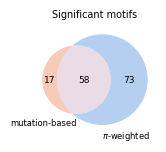

In [17]:
n = {c: int((E['category'] == c).sum()) for c in ('both', 'pi_only', 'genotype_only')}
fig, ax = plt.subplots(figsize=(1.6, 1.4))
v = venn2(subsets=(n['genotype_only'], n['pi_only'], n['both']), set_labels=('mutation-based', r'$\pi$-weighted'),
          set_colors=(CAT_COL['genotype_only'], CAT_COL['pi_only']), alpha=0.35, ax=ax)
for t in v.set_labels:
    t.set_fontsize(6)
ax.set_title('Significant motifs')
save(fig, 'fig5f_venn')

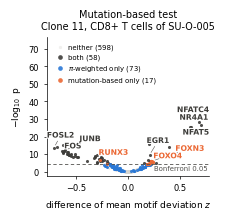

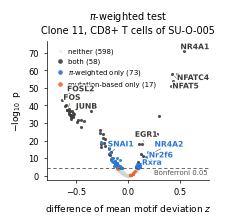

In [18]:
ANNOTATE = {'genotype': {'both': ['NR4A1', 'NFATC4', 'NFAT5', 'EGR1', 'FOS', 'JUNB', 'FOSL2'],
                         'genotype_only': ['FOXO4', 'FOXN3', 'RUNX3']},
            'pi': {'both': ['NR4A1', 'NFATC4', 'NFAT5', 'EGR1', 'FOS', 'JUNB', 'FOSL2'],
                   'pi_only': ['NR4A2', 'Nr2f6', 'Rxra', 'SNAI1']}}   # the motifs named in the paper's panels


def volcanoes(T, title, names, file):
    E_ = T[T['eligible']]
    lp = {s: -np.log10(np.maximum(2 * norm.sf(np.abs(E_[f'{s}__z'].to_numpy())), 1e-300)) for s in ('genotype', 'pi')}
    ymax = max(lp['genotype'].max(), lp['pi'].max()) * 1.08
    xlim = np.abs(np.r_[E_['genotype__avg_diff'], E_['pi__avg_diff']]).max() * 1.1
    thr = -np.log10(0.05 / len(T))
    for side, ttl in (('genotype', f'Mutation-based test\n{title}'), ('pi', f'$\\pi$-weighted test\n{title}')):
        fig, ax = plt.subplots(figsize=(2.1, 1.8))
        eff = E_[f'{side}__avg_diff'].to_numpy()
        for cat in ('none', 'both', 'pi_only', 'genotype_only'):
            m = (E_['category'] == cat).to_numpy()
            ax.scatter(eff[m], lp[side][m], s=(5 if cat != 'none' else 2.5), color=CAT_COL[cat],
                       alpha=(0.9 if cat != 'none' else 0.35), linewidths=0, rasterized=True,
                       label=f'{CAT_NAME[cat]} ({int(m.sum())})')
        ax.axhline(thr, color='#52514e', lw=0.6, ls=(0, (4, 3)))
        ax.text(xlim * 0.98, thr - 0.6, 'Bonferroni 0.05', fontsize=5, color='#52514e', va='top', ha='right')
        texts = []
        for cat, tfs in names.get(side, {}).items():
            m = ((E_['category'] == cat) & E_['tf'].isin(tfs)).to_numpy()
            for x_, y_, nm in zip(eff[m], lp[side][m], E_['tf'].to_numpy()[m]):
                texts.append(ax.text(x_, y_, nm, fontsize=5.5, color=CAT_COL[cat], fontweight='bold',
                                     path_effects=[pe.withStroke(linewidth=1.6, foreground='white')], zorder=6))
        ax.set_xlim(-xlim, xlim); ax.set_ylim(-ymax * 0.03, ymax)
        adjust_text(texts, x=eff, y=lp[side], ax=ax, arrowprops=dict(arrowstyle='-', color='#52514e', lw=0.4),
                iter_lim=1000)   # iterations, not seconds (the default, 1 s): the same every run
        ax.set_xlabel('difference of mean motif deviation $z$')
        ax.set_ylabel('$-\\log_{10}$ p')
        ax.legend(frameon=False, fontsize=5, loc='upper left', handletextpad=0.2, markerscale=1.5)
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_title(ttl)
        save(fig, f'{file}_{side}')


volcanoes(T12, f'Clone {K12}, CD8+ T cells of {DONOR12}', ANNOTATE, f'fig5gh_clone{K12}')

### Supplementary Fig. S8a–c: the tested cells, enlarged

The region of the UMAP containing the tested cells (0.5–99.5% quantiles of their coordinates): the cell types of the source study at its finer level, the clonal probability of Clone 11, and the 12879T>C genotype; other cells in light grey.

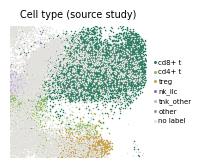

In [19]:
x0, x1 = np.quantile(xy[rows12, 0], [0.005, 0.995])
y0, y1 = np.quantile(xy[rows12, 1], [0.005, 0.995])
inview = (xy[:, 0] >= x0) & (xy[:, 0] <= x1) & (xy[:, 1] >= y0) & (xy[:, 1] <= y1)
tested = np.zeros(adata_mg.n_obs, bool)
tested[rows12] = True


def zoom_map(title):
    fig, ax = new_map()
    bg = inview & ~tested
    ax.scatter(xy[bg, 0], xy[bg, 1], s=S_ZOOM, color=DIM, linewidths=0, rasterized=RASTER)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title)
    return fig, ax


lv1 = lab['cell_type_lv1'].to_numpy()
LV1_COL = {'cd8+ t': '#2e7d63', 'cd4+ t': '#8fbf5a', 'treg': '#c7a14a', 'nk_ilc': '#8a6fae', 'tnk_other': '#c4b2da'}
fig, ax = new_map()
lv1_in = np.where(pd.isna(lv1), 'no label', np.where(np.isin(lv1, list(LV1_COL)), lv1, 'other'))
for t_, c_ in list(LV1_COL.items()) + [('other', '#9a9993'), ('no label', DIM)]:
    m_ = inview & (lv1_in == t_)
    ax.scatter(xy[m_, 0], xy[m_, 1], s=S_ZOOM, color=c_, linewidths=0, rasterized=RASTER, label=t_)
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=5, markerscale=2, handlelength=0.8,
          handletextpad=0.1)
ax.set_title('Cell type (source study)')
save(fig, 'supfig8a_celltype')

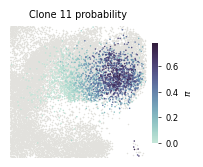

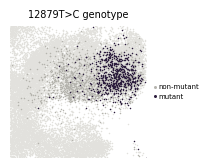

In [20]:
fig, ax = zoom_map(f'Clone {K12} probability')                          # the 2,077 tested cells
o = rows12[np.argsort(pi12[rows12])]
ax.scatter(xy[o, 0], xy[o, 1], c=pi12[o], cmap=PI_CMAP, vmin=0, vmax=pi12[rows12].max(), s=S_ZOOM, linewidths=0, rasterized=RASTER)
cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(0, pi12[rows12].max()), PI_CMAP), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
cb.outline.set_visible(False); cb.set_label(r'$\pi$')
save(fig, f'supfig8b_pi_clone{K12}')

fig, ax = zoom_map('12879T>C genotype')
for val, c_, lab_ in ((0, '#b5b4ae', 'non-mutant'), (1, VAF_CMAP(1.0), 'mutant')):
    m_ = rows12[g12 == val]
    ax.scatter(xy[m_, 0], xy[m_, 1], s=S_ZOOM, color=c_, linewidths=0, rasterized=RASTER, label=lab_)
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=5, markerscale=2, handlelength=0.8,
          handletextpad=0.1)
save(fig, 'supfig8c_genotype_12879')

The input of `04e_ovarian_motif_seurat_check.R`: the motif scores and the mutant calls of the tested cells.

In [21]:
Zfin = np.isfinite(z_all[zrow[rows12]]).all(0)
pd.DataFrame(z_all[zrow[rows12]][:, Zfin].T, index=motif_id[Zfin], columns=adata_mg.obs_names[rows12]).to_csv(f'{R_IN}/z.csv')
pd.DataFrame({'genotype': np.where(g12 == 1, 'pos', 'neg')}, index=adata_mg.obs_names[rows12]).to_csv(f'{R_IN}/groups.csv')
open(f'{R_IN}/clone.txt', 'w').write(str(K12))                    # the clone number, read by 04e
int(Zfin.sum()), len(rows12)

(746, 2077)

## 4. Every clone

One rule for every kept clone (fixed before the results were read): its variant is the one where its allele frequency most exceeds the shared component; its cells are all cells of the library holding most of its probability that are covered at that variant (no cell-type restriction, because the source study labels only 7 of the 11 libraries); mutant, VAF at least 0.10; a clone is tested if it has at least 30 mutant and 30 non-mutant cells.

For each tested clone: the two tests as above, the agreement of their effect sizes (Spearman correlation over the eligible motifs), and the enrichment of the mutant cells among these cells (30-nearest-neighbor graph of these cells on standardized $z$, 500 permutations).

In [22]:
pi_k = np.asarray(adata_mg.obsm['pi_deleted'], dtype=float)
phi_k = np.asarray(adata_mg.varm['phi_deleted'], dtype=float)
phi0 = np.asarray(adata_mg.varm['phi_0'], dtype=float).mean(1)
Zlat = np.asarray(adata_mg.obsm['z'], dtype=float)
excess = phi_k - phi0[:, None]
sets = []
for i, k in enumerate(kept):
    j = int(excess[:, i].argmax())
    m_lib = pd.Series(pi_k[:, i]).groupby(gsm).sum()
    lib = m_lib.idxmax()
    rows = np.flatnonzero((gsm == lib) & (D[:, j] >= 10))
    gt = (V[rows, j] >= 0.10).astype(float)
    sets.append(dict(clone=int(k), i=i, variant=variants[j], excess=float(excess[j, i]), library=lib,
                     library_share=float(m_lib.max() / m_lib.sum()), rows=rows, genotype=gt, weight=pi_k[rows, i],
                     n_mutant=int(gt.sum()), n_nonmutant=int((1 - gt).sum()),
                     tested=(gt.sum() >= 30) and ((1 - gt).sum() >= 30)))
pd.DataFrame(sets).drop(columns=['rows', 'genotype', 'weight', 'i']).round(3)

,clone,variant,excess,library,library_share,n_mutant,n_nonmutant,tested
0,0,3109T>C,0.013,GSM9096484,0.524,554,11046,True
1,1,3109T>C,0.026,GSM9096488,0.285,401,9381,True
2,2,310T>C,0.001,GSM9096488,0.222,4488,24,False
3,3,515A>G,0.198,GSM9096480,0.495,2041,1033,True
4,4,7738T>C,0.911,GSM9096483,0.763,5644,4591,True
5,5,7738T>C,0.996,GSM9096482,0.710,5906,1147,True
6,6,12071T>C,0.381,GSM9096484,0.762,1304,11883,True
7,7,11192G>A,0.108,GSM9096485,0.680,1132,6348,True
8,8,709G>A,0.499,GSM9096480,0.432,648,13522,True
9,9,7738T>C,0.994,GSM9096482,0.654,5906,1147,True


In [23]:
def enrichment_in(rows, mutant, rng, n_perm=500):
    zs = Zlat[rows]
    zs = (zs - zs.mean(0)) / np.maximum(zs.std(0), 1e-9)
    nb = NearestNeighbors(n_neighbors=31).fit(zs).kneighbors(zs, return_distance=False)[:, 1:]
    mut = mutant > 0
    purity = mut[nb[np.flatnonzero(mut)]].mean()
    null = np.empty(n_perm)
    for b in range(n_perm):
        p = np.zeros(len(mut), bool)
        p[rng.choice(len(mut), int(mut.sum()), replace=False)] = True
        null[b] = p[nb[np.flatnonzero(p)]].mean()
    return float((purity - null.mean()) / (1 - null.mean()))


summary = []
for s_ in sets:
    if not s_['tested']:
        continue
    rng = np.random.default_rng(1000 * s_['clone'])                  # one stream per clone
    enr = enrichment_in(s_['rows'], s_['genotype'], rng)
    T, _, keep = run_tests(s_['rows'], s_['genotype'], s_['weight'])
    T.to_csv(f'{OUT}/every_clone/clone{s_["clone"]}_motifs.csv', index=False)
    E_ = T[T['eligible']]
    summary.append(dict(clone=s_['clone'], variant=s_['variant'], excess=s_['excess'], library=s_['library'],
                        cells=len(s_['rows']), mutant=s_['n_mutant'], enrichment=enr,
                        mutation_based=int(E_['genotype__significant'].sum()), pi_weighted=int(E_['pi__significant'].sum()),
                        both=int((E_['category'] == 'both').sum()),
                        agreement=spearmanr(E_['genotype__avg_diff'], E_['pi__avg_diff'])[0]))
    volcanoes(T, f'Clone {s_["clone"]}, {s_["variant"]}, {s_["library"]}', {}, f'every_clone/motif_clone{s_["clone"]}')
    plt.close('all')
summary = pd.DataFrame(summary)
summary.to_csv(f'{OUT}/every_clone_summary.csv', index=False)
summary.round(3)

,clone,variant,excess,library,cells,mutant,enrichment,mutation_based,pi_weighted,both,agreement
0,0,3109T>C,0.013,GSM9096484,11600,554,0.007,19,592,18,-0.181
1,1,3109T>C,0.026,GSM9096488,9782,401,0.003,21,482,19,-0.669
2,3,515A>G,0.198,GSM9096480,3074,2041,0.026,0,294,0,-0.445
3,4,7738T>C,0.911,GSM9096483,10235,5644,0.852,699,690,688,0.999
4,5,7738T>C,0.996,GSM9096482,7053,5906,0.725,675,692,666,0.997
5,6,12071T>C,0.381,GSM9096484,13187,1304,0.060,423,612,412,0.926
6,7,11192G>A,0.108,GSM9096485,7480,1132,0.200,442,692,413,0.771
7,8,709G>A,0.499,GSM9096480,14170,648,0.110,88,487,88,0.897
8,9,7738T>C,0.994,GSM9096482,7053,5906,0.724,675,673,662,0.998
9,11,12879T>C,0.569,GSM9096485,7217,1022,0.386,511,621,510,0.995


Across clones: does the agreement of the two tests follow the enrichment of the mutant cells? Clones whose variant exceeds the shared component by less than 0.02 carry no variant of their own and are left out; clones that share a variant are not independent, so one clone per variant (the one with the largest excess) is used.

(11, 0.973)

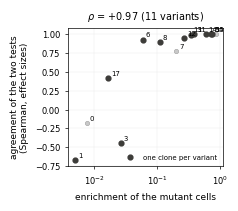

In [24]:
one = summary[summary['excess'] >= 0.02].sort_values('excess', ascending=False).drop_duplicates('variant')
fig, ax = plt.subplots(figsize=(2.0, 1.8))
ax.scatter(summary['enrichment'], summary['agreement'], s=10, c='#c8c8c8', edgecolor='#8a8a8a', lw=0.3, zorder=2)
ax.scatter(one['enrichment'], one['agreement'], s=12, c='#3d3c39', zorder=3, label='one clone per variant')
for _, r_ in summary.iterrows():
    ax.annotate(str(r_['clone']), (r_['enrichment'], r_['agreement']), fontsize=5, xytext=(2, 2), textcoords='offset points')
ax.set_xscale('symlog', linthresh=0.01, linscale=0.4)
ax.set_xlabel('enrichment of the mutant cells')
ax.set_ylabel('agreement of the two tests\n(Spearman, effect sizes)')
ax.set_title(f'$\\rho$ = {spearmanr(one["enrichment"], one["agreement"])[0]:+.2f} ({len(one)} variants)')
ax.legend(frameon=False, fontsize=5, loc='lower right')
ax.grid(alpha=0.25, lw=0.3)
save(fig, 'every_clone_agreement')
len(one), round(spearmanr(one['enrichment'], one['agreement'])[0], 3)

## 5. The numbers in the paper

`where` names the part of the paper: the Results section, a figure legend or alt text, a supplementary table or the Methods subsection.

In [25]:
R, M = 'Results (ovarian cohort)', 'Methods (Motif activity and clone-probability-weighted differential testing)'
rows = [('clone of 12879T>C', f'{R}; Fig. 5 legend', '11', str(K12)),
        ('donor of the tested library', f'{R}; Fig. 5 legend; Supp. Fig. S8 legend', 'SU-O-005', DONOR12),
        ('tested cells', f'{R}; Fig. 5 legend; Supp. Fig. S8 legend', '2,077', f'{len(rows12):,}'),
        ('mutant / non-mutant cells', M, '634 / 1,443', f'{int(g12.sum())} / {int((1 - g12).sum()):,}'),
        ('motifs', f'{R}; Fig. 5 legend; {M}', '746', str(len(E))),
        ('significant, mutation-based', R, '75', str(counts['mutation-based significant'])),
        ('significant, pi-weighted', R, '131', str(counts['pi-weighted significant'])),
        ('significant in both', f'{R}; Fig. 5 alt text', '58', str(counts['both'])),
        ('pi-weighted only', f'{R}; Fig. 5 alt text', '73', str(counts['pi-weighted only'])),
        ('mutation-based only', f'{R}; Fig. 5 alt text', '17', str(counts['mutation-based only'])),
        ('opposite directions', R, '0', str(counts['significant in both with opposite signs'])),
        ('correlation of the effect sizes', R, '0.93', f'{pearsonr(E["genotype__avg_diff"], E["pi__avg_diff"])[0]:.2f}'),
        ('mutant cells moved by the alt-read requirement', M, '13', str(int(moved.sum()))),
        ('median VAF of the mutant cells', M, '1.00', f'{np.median(V[rows12[g12 == 1], j12]):.2f}'),
        ('permuted pi: fraction of motifs with p < 0.05', M, '0.05', f'{frac.mean():.2f}')]
numbers = pd.DataFrame(rows, columns=['item', 'where', 'paper', 'computed'])
numbers['match'] = numbers['paper'] == numbers['computed']
numbers.to_csv(f'{OUT}/numbers_04d.csv', index=False)
pd.set_option('display.max_colwidth', 80)
numbers

,item,where,paper,computed,match
0,clone of 12879T>C,Results (ovarian cohort); Fig. 5 legend,11,11,True
1,donor of the tested library,Results (ovarian cohort); Fig. 5 legend; Supp. Fig. S8 legend,SU-O-005,SU-O-005,True
2,tested cells,Results (ovarian cohort); Fig. 5 legend; Supp. Fig. S8 legend,"2,077","2,077",True
3,mutant / non-mutant cells,Methods (Motif activity and clone-probability-weighted differential testing),"634 / 1,443","634 / 1,443",True
4,motifs,Results (ovarian cohort); Fig. 5 legend; Methods (Motif activity and clone-p...,746,746,True
5,"significant, mutation-based",Results (ovarian cohort),75,75,True
6,"significant, pi-weighted",Results (ovarian cohort),131,131,True
7,significant in both,Results (ovarian cohort); Fig. 5 alt text,58,58,True
8,pi-weighted only,Results (ovarian cohort); Fig. 5 alt text,73,73,True
9,mutation-based only,Results (ovarian cohort); Fig. 5 alt text,17,17,True
